# تصنيف شكاوى دمشق إلى مديريات متعددة (Multi-Label Text Classification)

## 1. تعريف المسألة

**المُدخل:** نص شكوى مواطن بالعربية (عامية شامية غالباً).
**المُخرج:** مجموعة فرعية من فضاء يضم **34 مديرية/جهة** — قد تكون مديرية واحدة، أو
أكثر، لنفس الشكوى.

هذه **ليست** مسألة Multi-Class (اختيار مديرية واحدة من 34). فحص البيانات (القسم 3
أدناه) يثبت أن نص الشكوى نفسه يتكرر أحياناً بأكثر من مديرية — أي أن بعض الشكاوى
تخص جهتين أو ثلاثاً في آن واحد (مثال واقعي من البيانات: "جرذان كبيرة وقمامة" ←
كل من الشؤون الصحية والنظافة). لذلك:

- الهدف `Y` مصفوفة multi-hot بشكل `(N, 34)`، لا متجه فئة واحدة.
- التنبؤ لكل مديرية **مستقل** (قرار ثنائي منفصل)، لا اختيار واحد عبر `argmax`/`softmax`.
- التقييم يستخدم مقاييس multi-label (micro/macro/weighted F1، Hamming loss، دقة
  المجموعة الكاملة subset accuracy)، لا دقة multi-class عادية.

> **ملاحظة منهجية:** هذا النوتبوك إعادة بناء كاملة ونظيفة لنوتبوك سابق كان يحتوي
> تجربة single-label (imbalance handling على هدف فئة واحدة: SMOTE، ROS/RUS،
> StratifiedKFold أحادي، argmax) إلى جانب عمل multi-label لاحق. تلك التجربة
> single-label أُزيلت بالكامل هنا — لم تعد ذات معنى بعد ثبوت أن الحقيقة الأرضية
> multi-label. كل ما تبقّى أدناه هو مسار multi-label واحد متّسق من البداية للنهاية.


## 2. تحميل البيانات

نُعيد استخدام مُحلِّل CSV مخصص (لا `pandas.read_csv` مباشرة) لأن الملف يحتوي حقول
شكوى تمتد لعدة أسطر فعلية وفواصل غير متوقعة أحياناً — `read_csv` القياسي يُسقط أو
يُشوّه عشرات الصفوف بصمت (تحقّقنا من ذلك). فضاء المديريات الـ34 معروف مسبقاً من
مصدر البيانات نفسه ونستخدمه كمرجع ثابت للمطابقة أثناء التحليل.


In [1]:
departments = [
  "مديرية الصيانة و الإنارة",
  "مديرية هندسة المرور والنقل",
  "مديرية دمشق القديمة",
  "دوائر الخدمات",
  "الشركة العامة للصرف الصحي المركزية",
  "مديرية المهن والرخص",
  "مديرية الحدائق",
  "مديرية الأملاك",
  "مديرية البيئة",
  "مديرية النظافة",
  "مديرية الشؤون الصحية",
  "مديرية التنظيم والتخطيط العمراني",
  "مديرية الإنارة",
  "مديرية تنفيذ المشروع التشريعي 66",
  "مديرية التجارة الداخلية وحماية المستهلك المركزية",
  "مديرية الاستثمار والصيانة (مياه الشرب) المركزية",
  "المؤسسة العامة لمياه الشرب المركزية",
  "مديرية الزراعة المركزية",
  "الشركة العامة للكهرباء المركزية",
  "مديرية النقل المركزية",
  "مديرية الاتصالات المركزية",
  "مديرية دفن الموتى",
  "مديرية المركبات والرحبات",
  "مديرية المجالس المحلية ومكاتبها التنفذية",
  "مديرية القضايا والشؤون القانونية",
  "مديرية سياحة المركزية",
  "مديرية التربية والتعليم المركزية",
  "مديرية الطوارئ والكوارث المركزية",
  "مديرية الأنشطة الرياضية والثقافية والاجتماعية",
  "مديرية الرقابة الداخلية",
  "مديرية مالية المركزية",
  "مديرية الاشراف",
  "مديرية الصحة المركزية",
  "مديرية الأمانة العامة"
]

In [2]:
data_path = "damgov_data.csv"

with open(data_path, "r", encoding="utf-8") as f:
    lines = f.readlines()

print("Physical lines:", len(lines))

Physical lines: 30665


In [3]:
# ✅ [مصححة — Claude]
# ما تغيّر:
#   1) تجريد فاصل الـCSV اللاحق عندما يكون حقل الشكوى غير مقتبس، مثل السطر:
#          qeqwe,"مديرية الصيانة و الإنارة"
#      هذا السطر يطابق النمط الرابع فقط، فكانت الفاصلة تبقى ملتصقة بنهاية النص
#      وتُنتج 76 صفاً مشوّهاً مثل "test," و "قمامة," و "تزفيت,".
#   2) الإبلاغ عن حالة المُحلِّل بدل ابتلاعها بصمت. مؤشر الخلل الحقيقي هو "أسطر
#      معلّقة لم تُغلق" — أي رقم غير الصفر يعني سجلات ضاعت في نهاية الملف. الاقتباسات
#      غير المتوازنة داخل النصوص تدفع أسطراً للاندماج مع السجل التالي (رُصدت حالة
#      اندمجت فيها ثلاث شكاوى منفصلة في سجل واحد).
# لماذا: الفاصلة الملتصقة تُنتج توكنات وهمية، والاندماج الصامت يخلق سجلات مركّبة
#        بتسمية واحدة — وكلاهما ضجيج يدخل التدريب دون أن يظهر في أي فحص.

records = []
current_complaint = []

n_continuation_lines = 0   # أسطر لم تُنهِ سجلاً — معظمها تكملة شكاوى متعددة الأسطر (طبيعي)
n_comma_fixed = 0       # صفوف صُحّحت فيها الفاصلة اللاحقة

for line in lines[1:]:  # skip CSV header

    line = line.rstrip("\n\r")

    # أي نمط من أنماط نهاية السطر يطابق؟ الترتيب مهم: الأعم أولاً.
    matched_department = None
    matched_pattern = None
    matched_suffix = None

    for department in departments:

        for pattern_id, suffix in enumerate((
            f'","{department}"',   # 0: حقل شكوى مقتبس + مديرية مقتبسة
            f'",{department}"',    # 1
            f',{department}',      # 2: مديرية غير مقتبسة (الفاصلة مستهلكة ضمن اللاحقة)
            f'"{department}"',     # 3: حقل شكوى غير مقتبس  <-- مصدر الخلل
        )):
            if line.endswith(suffix):
                matched_department = department
                matched_pattern = pattern_id
                matched_suffix = suffix
                break

        if matched_department is not None:
            break

    if matched_department is not None:

        complaint_part = line[:-len(matched_suffix)]

        # ✅ النمط 3 يعني أن حقل الشكوى غير مقتبس، فالفاصلة التي قبل المديرية
        #    هي فاصل CSV وليست جزءاً من نص الشكوى.
        if matched_pattern == 3 and complaint_part.endswith(","):
            complaint_part = complaint_part[:-1]
            n_comma_fixed += 1

        current_complaint.append(complaint_part)

        complaint = "\n".join(current_complaint)

        # Remove CSV opening quote
        if complaint.startswith('"'):
            complaint = complaint[1:]

        # Remove CSV closing quote
        if complaint.endswith('"'):
            complaint = complaint[:-1]

        records.append([
            complaint,
            matched_department
        ])

        current_complaint = []

    else:
        # This is part of a multiline complaint (or a line orphaned by broken quoting)
        n_continuation_lines += 1
        current_complaint.append(line)

print(f"سجلات مستخرجة                      : {len(records)}")
print(f"فواصل لاحقة صُحّحت                  : {n_comma_fixed}")
print(f"أسطر تكملة (شكاوى متعددة الأسطر)   : {n_continuation_lines}")
print(f"أسطر معلّقة لم تُغلق (يجب أن تكون 0) : {len(current_complaint)}")


سجلات مستخرجة                      : 17021
فواصل لاحقة صُحّحت                  : 76
أسطر تكملة (شكاوى متعددة الأسطر)   : 13643
أسطر معلّقة لم تُغلق (يجب أن تكون 0) : 0


In [4]:
import pandas as pd

data = pd.DataFrame(
    records,
    columns=["complaint", "department"]
)

print("Dataset Shape:", data.shape)

print("Number of departments:",
      data["department"].nunique())

print("\nDepartments:")
print(data["department"].value_counts())

Dataset Shape: (17021, 2)
Number of departments: 34

Departments:
department
دوائر الخدمات                                       4349
مديرية هندسة المرور والنقل                          3406
مديرية الصيانة و الإنارة                            2691
مديرية النظافة                                      1532
الشركة العامة للصرف الصحي المركزية                  1522
مديرية الحدائق                                       861
الشركة العامة للكهرباء المركزية                      493
مديرية الاستثمار والصيانة (مياه الشرب) المركزية      388
مديرية دمشق القديمة                                  332
مديرية المهن والرخص                                  294
مديرية الزراعة المركزية                              243
مديرية الأملاك                                       185
المؤسسة العامة لمياه الشرب المركزية                  170
مديرية النقل المركزية                                129
مديرية الشؤون الصحية                                 124
مديرية الاتصالات المركزية                            114
مديرية البي

## 3. تنظيف البيانات (Data Cleaning)

نُسقط فقط **الصفوف المكررة تماماً** (نفس نص الشكوى + نفس المديرية) والشكاوى
الفارغة/بيضاء. **لا نُسقط** نصاً مكرراً بمديرية مختلفة — هذا هو بالضبط دليل
multi-label الذي نبني عليه القسم التالي، وحذف أي نسخة منه سيكون قراراً تعسفياً
يُتلف الحقيقة الأرضية.


In [5]:
import re
import unicodedata
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 40)

SEED = 42
np.random.seed(SEED)

df = data.copy()
n_before = len(df)

# صفوف مكررة تماماً (نفس النص + نفس المديرية) -> ضجيج تكراري آمن الحذف
exact_dupes = df.duplicated(subset=["complaint", "department"]).sum()
df = df.drop_duplicates(subset=["complaint", "department"]).reset_index(drop=True)

# شكاوى فارغة/بيضاء -> غير قابلة للاستخدام
empty_mask = df["complaint"].astype(str).str.strip().eq("")
n_empty = int(empty_mask.sum())
df = df[~empty_mask].reset_index(drop=True)

print(f"صفوف قبل التنظيف        : {n_before:,}")
print(f"صفوف مكررة تماماً حُذفت : {exact_dupes:,}")
print(f"شكاوى فارغة حُذفت       : {n_empty:,}")
print(f"صفوف بعد التنظيف        : {len(df):,}")


صفوف قبل التنظيف        : 17,021
صفوف مكررة تماماً حُذفت : 589
شكاوى فارغة حُذفت       : 0
صفوف بعد التنظيف        : 16,432


## 4. التطبيع اللغوي العربي (Arabic Normalization)

تطبيع خفيف قابل للتهيئة (توحيد الألف/الياء/الهمزة، تجميع التكرار الحرفي مثل
"قمااامة"، إزالة التشكيل والترقيم، تحويل الأرقام). هذه دالة أداتية عامة لا علاقة
لها بصيغة الهدف (single- أو multi-label) — تبقى صحيحة كما هي.


In [6]:
ARABIC_DIACRITICS = re.compile(r'[\u0617-\u061A\u064B-\u0652\u0670\u0640]')  # tashkeel + tatweel
TATWEEL = '\u0640'
REPEATED_CHAR = re.compile(r'(.)\1{2,}')  # 3+ تكرارات لنفس الحرف -> تُجمَّع إلى حرفين
ALEF_VARIANTS = re.compile(r'[إأآا]')
YEH_VARIANTS = re.compile(r'ى')
HAMZA_ON_WAW_YEH = re.compile(r'[ؤئ]')
ARABIC_INDIC_DIGITS = str.maketrans('٠١٢٣٤٥٦٧٨٩', '0123456789')
PUNCT_RE = re.compile(r'[\.\,\!\?\;\:\-\_\(\)\[\]\{\}\"\'\/\\\|\+\=\*\&\^\%\$\#\@\~\`٪،؛؟…“”‘’«»]')
MULTISPACE = re.compile(r'\s+')


def normalize_arabic(text, remove_diacritics=True, normalize_alef=True, normalize_yeh=True,
                      normalize_hamza=True, collapse_repeats=True,
                      remove_punctuation=True, normalize_digits=True):
    """تطبيع عربي خفيف. الإعدادات الافتراضية هي التي استُخدمت طوال النوتبوك."""
    if not isinstance(text, str):
        text = "" if text is None else str(text)
    text = unicodedata.normalize('NFKC', text)
    text = ARABIC_DIACRITICS.sub('', text) if remove_diacritics else text.replace(TATWEEL, '')
    if normalize_alef: text = ALEF_VARIANTS.sub('ا', text)
    if normalize_yeh: text = YEH_VARIANTS.sub('ي', text)
    if normalize_hamza: text = HAMZA_ON_WAW_YEH.sub('ء', text)
    if collapse_repeats: text = REPEATED_CHAR.sub(r'\1\1', text)
    if normalize_digits: text = text.translate(ARABIC_INDIC_DIGITS)
    if remove_punctuation: text = PUNCT_RE.sub(' ', text)
    text = MULTISPACE.sub(' ', text).strip()
    return text


df["clean"] = df["complaint"].apply(normalize_arabic)
df = df[df["clean"].str.len() > 0].reset_index(drop=True)

print("أمثلة تطبيع:")
for s in df["complaint"].sample(3, random_state=SEED):
    print(" raw  :", s[:80])
    print(" clean:", normalize_arabic(s)[:80])
    print()


أمثلة تطبيع:
 raw  : سيارات قديمة مركونة
 clean: سيارات قديمة مركونة

 raw  : يرجى تزفيت مكان في الشارع تضرر منه الكثير من الناس المارّة
 clean: يرجي تزفيت مكان في الشارع تضرر منه الكثير من الناس المارة

 raw  : اعمدة الكهربا طالعة الشرايط منها  اطفال  المدارس يضعو ايدهم على الاعمدة الرجاء ق
 clean: اعمدة الكهربا طالعة الشرايط منها اطفال المدارس يضعو ايدهم علي الاعمدة الرجاء قبو



## 5. بناء الحقيقة الأرضية متعددة التسميات (Multi-Label Ground Truth)

البيانات لا تحتوي عمود "قائمة مديريات". الشكوى متعددة المديريات تظهر كصفّين (أو
أكثر) بنفس نص الشكوى، كل صف بمديرية مختلفة. نجمّع الصفوف حسب نص الشكوى الفريد
فنحصل على صف واحد لكل شكوى، وعمود `departments` هو *قائمة* المديريات الصحيحة لها.

**فضاء التسميات `LABEL_SPACE` هو قائمة الـ34 مديرية الكاملة كما وردت من مصدر
البيانات (خلية §2) — لا نُسقط أي مديرية هنا مهما كانت نادرة.** الفلترة/الاستبعاد
ممنوعة عند هذه المرحلة؛ التعامل مع الندرة يكون بالتوثيق لاحقاً (§7)، لا بالحذف.


In [7]:
from sklearn.preprocessing import MultiLabelBinarizer

# فضاء التسميات الكامل والثابت — 34 مديرية، بلا استثناء
LABEL_SPACE = sorted(departments)
assert len(LABEL_SPACE) == 34, f"expected 34 labels, got {len(LABEL_SPACE)}"

grouped = (
    df.groupby("complaint")
    .agg(clean=("clean", "first"),
         departments=("department", lambda s: sorted(set(s))))
    .reset_index()
)
grouped["n_labels"] = grouped["departments"].apply(len)

mlb = MultiLabelBinarizer(classes=LABEL_SPACE)
Y_all = mlb.fit_transform(grouped["departments"])

assert Y_all.shape[1] == 34, "Y must have exactly 34 columns"
assert list(mlb.classes_) == LABEL_SPACE, "column order must match LABEL_SPACE exactly"

print(f"عدد الشكاوى الفريدة (samples) : {len(grouped):,}")
print(f"عدد التسميات (labels)         : {Y_all.shape[1]}")
print(f"شكل مصفوفة الهدف Y            : {Y_all.shape}   (multi-hot, Y ∈ {{0,1}}^(N×34))")
print()
print("توزيع عدد المديريات لكل شكوى:")
print(grouped["n_labels"].value_counts().sort_index())
print()
print(f"أدنى عدد تسميات لكل عيّنة : {grouped['n_labels'].min()}")
print(f"وسيط                     : {grouped['n_labels'].median()}")
print(f"متوسط                    : {grouped['n_labels'].mean():.4f}")
print(f"أقصى عدد تسميات لكل عيّنة : {grouped['n_labels'].max()}")
print(f"\nنسبة الشكاوى متعددة التسمية (>1 مديرية): {(grouped['n_labels'] > 1).mean()*100:.2f}%  "
      f"({(grouped['n_labels'] > 1).sum()} شكوى)")

print("\nأمثلة على شكاوى مرتبطة بأكثر من مديرية:")
for _, row in grouped[grouped["n_labels"] > 1].sample(4, random_state=SEED).iterrows():
    print(f" - {row['complaint'][:70]!r}\n     -> {row['departments']}")


عدد الشكاوى الفريدة (samples) : 15,758
عدد التسميات (labels)         : 34
شكل مصفوفة الهدف Y            : (15758, 34)   (multi-hot, Y ∈ {0,1}^(N×34))

توزيع عدد المديريات لكل شكوى:
n_labels
1    15114
2      615
3       29
Name: count, dtype: int64

أدنى عدد تسميات لكل عيّنة : 1
وسيط                     : 1.0
متوسط                    : 1.0427
أقصى عدد تسميات لكل عيّنة : 3

نسبة الشكاوى متعددة التسمية (>1 مديرية): 4.09%  (644 شكوى)

أمثلة على شكاوى مرتبطة بأكثر من مديرية:
 - 'يوجد ردم وقمامة واغلب الناس عم ترمي بالموقع نفسو \nهاذا طريق رئيسي لمدخ'
     -> ['دوائر الخدمات', 'مديرية الصيانة و الإنارة', 'مديرية النظافة']
 - 'هذه الشكوى للمره العاشره ولم يستجاب طلبنا مضمون الشكوى \nهبوط الريكارات'
     -> ['الشركة العامة للصرف الصحي المركزية', 'دوائر الخدمات']
 - 'هنالك منزل سقفه مفتوح مهجور  يعج بالقمامة و الخرداوات والقوارض .تحت بن'
     -> ['دوائر الخدمات', 'مديرية المهن والرخص']
 - 'جرذان كبيرة وقمامة منذ سنوات تؤذي السكان'
     -> ['مديرية الشؤون الصحية', 'مديرية النظافة']


## 6. إحصاءات التسميات (Label Statistics) — قبل التقسيم

تكرار كل مديرية عبر كامل البيانات (34 صفاً، بلا استثناء)، مرتّبة تصاعدياً لإظهار
الندرة الشديدة في الذيل بوضوح.


,total_count
مديرية الأمانة العامة,1
مديرية الصحة المركزية,1
مديرية الطوارئ والكوارث المركزية,1
مديرية مالية المركزية,1
مديرية الإنارة,2
مديرية الأنشطة الرياضية والثقافية والاجتماعية,2
مديرية الرقابة الداخلية,4
مديرية القضايا والشؤون القانونية,5
مديرية دفن الموتى,5
مديرية تنفيذ المشروع التشريعي 66,6



مجموع العينات (شكاوى فريدة): 15,758
عدد التسميات (labels)      : 34

تسميات بـ total_count = 0   : 0
تسميات بـ total_count = 1   : 4
تسميات بـ total_count < 3   : 6
تسميات بـ total_count < 5   : 7
تسميات بـ total_count < 10  : 14


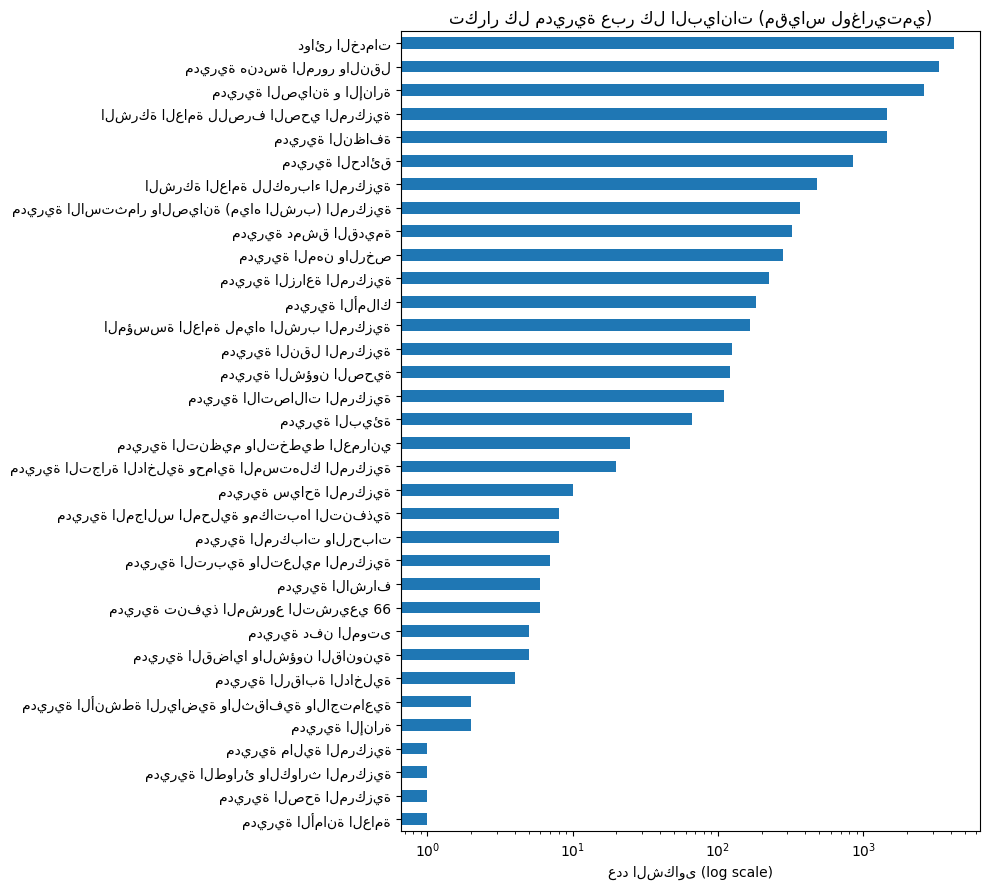

In [8]:
total_support = pd.Series(Y_all.sum(axis=0), index=LABEL_SPACE, name="total_count").sort_values()

display(total_support.to_frame())

print(f"\nمجموع العينات (شكاوى فريدة): {len(grouped):,}")
print(f"عدد التسميات (labels)      : {len(LABEL_SPACE)}")
print()
print(f"تسميات بـ total_count = 0   : {int((total_support == 0).sum())}")
print(f"تسميات بـ total_count = 1   : {int((total_support == 1).sum())}")
print(f"تسميات بـ total_count < 3   : {int((total_support < 3).sum())}")
print(f"تسميات بـ total_count < 5   : {int((total_support < 5).sum())}")
print(f"تسميات بـ total_count < 10  : {int((total_support < 10).sum())}")

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 9))
total_support.plot(kind="barh")
plt.xscale("log")
plt.title("تكرار كل مديرية عبر كل البيانات (مقياس لوغاريتمي)")
plt.xlabel("عدد الشكاوى (log scale)")
plt.tight_layout()
plt.show()


## 7. تقسيم Train / Validation / Test (Multi-Label-aware)

`sklearn.train_test_split(..., stratify=y)` لا يقبل هدفاً multi-hot، و
`StratifiedKFold` العادي يفترض عمود فئة واحدة — كلاهما غير صالح هنا. نستخدم
**Iterative Stratification** (حزمة `iterstrat`، تطبيق خوارزمية Sechidis et al.
2011 القياسية لتوزيع بيانات multi-label بعدالة نسبية عبر التقسيمات)، وهي فعلياً
متاحة في البيئة الحالية — تحققنا من ذلك بدل افتراضه.

**سياسة صريحة للتسميات النادرة جداً** (فوق ما توفره `iterstrat` تلقائياً):
مديرية بـ `total_count == 1` **يجب** أن تبقى عيّنتها الوحيدة في **train** — لا
يمكن للمودل أن يتعلّم تسمية من صفر أمثلة تدريب. نتحقق بعد التقسيم الأساسي، وأي
عيّنة من هذا النوع سقطت في val/test تُنقل قسراً إلى train (نطبعها صراحة أدناه).

الانقسام مستهدف تقريبي 70/15/15، لكنه **على مستوى نص الشكوى الفريد** (لا الصف)
لمنع تسرّب نفس النص بين التقسيمات.


In [10]:
!pip install iterative-stratification

In [11]:
# الحزمة متاحة فعلياً في هذه البيئة (تحقّقنا بالتثبيت والاستيراد قبل الاعتماد عليها)
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

X_idx = np.arange(len(grouped))

msss1 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(msss1.split(X_idx, Y_all))

msss2 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_rel_idx, test_rel_idx = next(msss2.split(temp_idx, Y_all[temp_idx]))
val_idx = temp_idx[val_rel_idx]
test_idx = temp_idx[test_rel_idx]

split_arr = np.array(["?"] * len(grouped), dtype=object)
split_arr[train_idx] = "train"
split_arr[val_idx] = "val"
split_arr[test_idx] = "test"
grouped["split"] = split_arr

print("توزيع الحجم بعد iterative stratification:")
print(grouped["split"].value_counts())
print(f"النِّسَب الفعلية: train={grouped['split'].eq('train').mean():.1%}  "
      f"val={grouped['split'].eq('val').mean():.1%}  test={grouped['split'].eq('test').mean():.1%}")

# --- سياسة صريحة: تسمية بعيّنة وحيدة (total_count==1) يجب أن تبقى في train ---
singleton_labels = total_support[total_support == 1].index.tolist()
moved = 0
for lbl in singleton_labels:
    li = LABEL_SPACE.index(lbl)
    for r in np.where(Y_all[:, li] == 1)[0]:
        if grouped.loc[r, "split"] != "train":
            grouped.loc[r, "split"] = "train"
            moved += 1

print(f"\nتسميات بعيّنة وحيدة (total_count==1): {singleton_labels}")
print(f"عيّنات نُقلت قسراً إلى train لضمان وجودها في التدريب: {moved}")
print(grouped["split"].value_counts())

train_g = grouped[grouped.split == "train"].reset_index(drop=True)
val_g   = grouped[grouped.split == "val"].reset_index(drop=True)
test_g  = grouped[grouped.split == "test"].reset_index(drop=True)

Y_tr = mlb.transform(train_g["departments"])
Y_va = mlb.transform(val_g["departments"])
Y_te = mlb.transform(test_g["departments"])

print(f"\ntrain={len(train_g):,}  val={len(val_g):,}  test={len(test_g):,}")


توزيع الحجم بعد iterative stratification:
split
train    11021
test      2384
val       2353
Name: count, dtype: int64
النِّسَب الفعلية: train=69.9%  val=14.9%  test=15.1%

تسميات بعيّنة وحيدة (total_count==1): ['مديرية الأمانة العامة', 'مديرية الصحة المركزية', 'مديرية الطوارئ والكوارث المركزية', 'مديرية مالية المركزية']
عيّنات نُقلت قسراً إلى train لضمان وجودها في التدريب: 0
split
train    11021
test      2384
val       2353
Name: count, dtype: int64

train=11,021  val=2,353  test=2,384


## 7.1 دعم التسميات النادرة وحدود التقييم (Rare Label Support and Evaluation Limitations)

نقاط صريحة يجب إبقاؤها حاضرة في كل قراءة لاحقة لنتائج هذا النوتبوك:

1. **فضاء المهمة النهائي هو 34 تسمية**، بلا استثناء. هذا لا يتغيّر في أي قسم لاحق.
2. بعض التسميات لا تملك أمثلة كافية لتقييم موثوق train/validation/test في آن
   واحد — هذا **مستحيل رياضياً** لتسمية بعيّنة أو عيّنتين فقط في كل البيانات.
3. **نقص الدعم لا يُسقط التسمية من المهمة تلقائياً.** المودل يبقى بـ34 مُخرَجاً
   دوماً، حتى للتسميات النادرة جداً.
4. **أهلية Cross-Validation ≠ أبعاد مخرجات المودل.** مجموعتان مختلفتان تماماً:
   `CV_ELIGIBLE_LABELS` (تسميات يمكن قياس أدائها بثبات عبر الطيّات) مقابل
   `LABEL_SPACE` (كل الـ34 التي يتنبأ بها المودل فعلياً). لا نخلط بينهما.
5. مقاييس التسميات النادرة **تُقرأ دوماً مع عدد دعمها (support)** بجانبها — رقم
   بلا سياق الدعم مضلِّل.
6. **لا مقياس مُختلَق.** تسمية بصفر أمثلة اختبار تُقيَّم صراحةً كـ`N/A`، لا كصفر
   مموَّه يوحي بفشل قابل للقياس.

الخلية التالية تحسب فعلياً — لا تفترض — عتبات الأهلية من توزيع البيانات نفسه.


In [12]:
support_table = pd.DataFrame({
    "total": Y_all.sum(axis=0),
    "train": Y_tr.sum(axis=0),
    "val": Y_va.sum(axis=0),
    "test": Y_te.sum(axis=0),
}, index=LABEL_SPACE).sort_values("total")

display(support_table)

# --- عتبات مُشتقّة من البيانات نفسها، موثّقة صراحة، لا مُخترَعة اعتباطاً ---

# CV: 5 طيّات على train+val => نتوقع دعماً معقولاً فقط إن كان يكفي لعدة أمثلة
# مستقلة لكل طيّة. 10 أمثلة على 5 طيّات = ~2 لكل طيّة في المتوسط، وهو أدنى حد
# نعتبره كافياً لعدم اعتماد نتيجة الطيّة على عيّنة واحدة بمفردها.
CV_MIN_SUPPORT = 10
cv_pool_support = Y_tr.sum(axis=0) + Y_va.sum(axis=0)  # المجمّع المستخدم فعلياً في CV (القسم 9)
CV_ELIGIBLE_LABELS = [LABEL_SPACE[i] for i in range(34) if cv_pool_support[i] >= CV_MIN_SUPPORT]
CV_ELIGIBLE_IDX = [LABEL_SPACE.index(l) for l in CV_ELIGIBLE_LABELS]
CV_INELIGIBLE_LABELS = [l for l in LABEL_SPACE if l not in CV_ELIGIBLE_LABELS]

# Validation: عتبة دنيا لعدد الإيجابيات الحقيقية في val قبل الوثوق بأي قرار
# (عتبة تصنيف أو مقارنة نماذج) يُبنى على أداء تلك التسمية تحديداً.
VAL_MIN_SUPPORT = 5
VALIDATION_RELIABLE_LABELS = [LABEL_SPACE[i] for i in range(34) if Y_va.sum(axis=0)[i] >= VAL_MIN_SUPPORT]

# Test: نفس المنطق للتقرير النهائي — تسمية بدعم اختبار ضعيف جداً تُصنَّف كذلك صراحة.
TEST_MIN_SUPPORT = 5
TEST_RELIABLE_LABELS = [LABEL_SPACE[i] for i in range(34) if Y_te.sum(axis=0)[i] >= TEST_MIN_SUPPORT]
TEST_ELIGIBLE_IDX = [LABEL_SPACE.index(l) for l in TEST_RELIABLE_LABELS]
ZERO_TEST_SUPPORT_LABELS = [LABEL_SPACE[i] for i in range(34) if Y_te.sum(axis=0)[i] == 0]

print(f"CV_ELIGIBLE_LABELS         : {len(CV_ELIGIBLE_LABELS)}/34  "
      f"(عتبة: دعم train+val >= {CV_MIN_SUPPORT})")
print(f"  غير مؤهّلة لـCV: {CV_INELIGIBLE_LABELS}")
print(f"\nVALIDATION_RELIABLE_LABELS : {len(VALIDATION_RELIABLE_LABELS)}/34  "
      f"(عتبة: دعم val >= {VAL_MIN_SUPPORT})")
print(f"\nTEST_RELIABLE_LABELS       : {len(TEST_RELIABLE_LABELS)}/34  "
      f"(عتبة: دعم test >= {TEST_MIN_SUPPORT})")
print(f"  صفر دعم في test (N/A حتماً): {ZERO_TEST_SUPPORT_LABELS}")

print("\n>>> الخلاصة: المودل سيبقى بـ34 مُخرَجاً طوال النوتبوك. أهلية CV/val/test "
      "تُستخدم فقط لتفسير المقاييس، لا لتغيير فضاء المهمة.")


,total,train,val,test
مديرية الأمانة العامة,1,1,0,0
مديرية الصحة المركزية,1,1,0,0
مديرية الطوارئ والكوارث المركزية,1,1,0,0
مديرية مالية المركزية,1,1,0,0
مديرية الإنارة,2,1,0,1
مديرية الأنشطة الرياضية والثقافية والاجتماعية,2,1,0,1
مديرية الرقابة الداخلية,4,3,0,1
مديرية القضايا والشؤون القانونية,5,3,1,1
مديرية دفن الموتى,5,3,1,1
مديرية تنفيذ المشروع التشريعي 66,6,4,1,1


CV_ELIGIBLE_LABELS         : 19/34  (عتبة: دعم train+val >= 10)
  غير مؤهّلة لـCV: ['مديرية الأمانة العامة', 'مديرية الأنشطة الرياضية والثقافية والاجتماعية', 'مديرية الإنارة', 'مديرية الاشراف', 'مديرية التربية والتعليم المركزية', 'مديرية الرقابة الداخلية', 'مديرية الصحة المركزية', 'مديرية الطوارئ والكوارث المركزية', 'مديرية القضايا والشؤون القانونية', 'مديرية المجالس المحلية ومكاتبها التنفذية', 'مديرية المركبات والرحبات', 'مديرية تنفيذ المشروع التشريعي 66', 'مديرية دفن الموتى', 'مديرية سياحة المركزية', 'مديرية مالية المركزية']

VALIDATION_RELIABLE_LABELS : 17/34  (عتبة: دعم val >= 5)

TEST_RELIABLE_LABELS       : 17/34  (عتبة: دعم test >= 5)
  صفر دعم في test (N/A حتماً): ['مديرية الأمانة العامة', 'مديرية الصحة المركزية', 'مديرية الطوارئ والكوارث المركزية', 'مديرية مالية المركزية']

>>> الخلاصة: المودل سيبقى بـ34 مُخرَجاً طوال النوتبوك. أهلية CV/val/test تُستخدم فقط لتفسير المقاييس، لا لتغيير فضاء المهمة.


## 8. النموذج الأساسي التقليدي — TF-IDF + Multi-Label (OneVsRestClassifier)

الصياغة: `TfidfVectorizer` (حروف char_wb، ملائم للعامية العربية غير المُقعَّدة
إملائياً) → `OneVsRestClassifier(LinearSVC(class_weight="balanced"))`. هذا يدرّب
**34 مصنّفاً ثنائياً مستقلاً** — واحد لكل مديرية ("هل تخص هذه الشكوى المديرية X؟
نعم/لا") — لا مصنّفاً واحداً متعدد الفئات. النتيجة: يمكن تفعيل عدة مصنّفات معاً
لنفس الشكوى، وهذا هو المطلوب بالضبط لـmulti-label.

**`class_weight="balanced"` هنا صالح ومُبرَّر:** يعمل داخل كل مصنّف ثنائي مستقل
على حدة (لا عبر فئات متنافسة كما في multi-class)، ويعالج اختلال التوازن الحاد بين
"تخص هذه المديرية" (نادر لمعظم المديريات) و"لا تخصها" (الغالب) — بلا بيانات
اصطناعية وبلا خطر تسرّب. لا حاجة لأي تقنية إعادة توازن إضافية (انظر التبرير في
القسم التالي).

**عن `decision_function`:** `LinearSVC.decision_function` تُخرج مسافة موقّعة عن
الحد الفاصل، **وليست احتمالاً**. نُمرّرها عبر `sigmoid` (`scipy.special.expit`)
فقط لتحويلها إلى نطاق `[0,1]` صالح للمقارنة بعتبة — هذا تحويل رتيب (monotonic) لا
معايرة إحصائية، ونُسمّي الدالة `sigmoid_scores` لا `predict_proba` لتفادي الإيحاء
الخاطئ بأنها احتمال معايَر.


### تدقيق: هل نحتاج SMOTE / RandomOverSampler / RandomUnderSampler هنا؟

النوتبوك السابق جرّب `SMOTE`، `RandomOverSampler`، و`RandomUnderSampler` — لكن
تلك التجارب كانت مبنية على هدف **single-label فئة واحدة** (`y` عمود نصي واحد)،
وهي غير قابلة للنقل المباشر إلى multi-label: `imbalanced-learn` القياسي
(`SMOTE`/`RandomOverSampler`/`RandomUnderSampler`) مصمّم لمتجه فئة واحد `y`، لا
لمصفوفة multi-hot `(N, 34)` — تطبيقها كما هي على هدف multi-hot إما يفشل أو
يُعيد تفسير كل تركيبة تسميات كـ"فئة" منفصلة (سلوك غير مقصود وغير مفيد).

**القرار لهذا النوتبوك: لا إعادة توازن على مستوى العيّنات.** لم يُنفَّذ أي إصدار
multi-label-compatible من SMOTE (مثل `MLSMOTE`) هنا، فلا ندّعي أننا اختبرناه. بدل
ذلك نعتمد **فقط** على `class_weight="balanced"` داخل كل مصنّف ثنائي مستقل (القسم
السابق) — وهو كافٍ منطقياً هنا لأن المشكلة تتحلّل أصلاً إلى 34 مسألة ثنائية
مستقلة، وكل واحدة منها يعالجها `class_weight` مباشرة بلا بيانات اصطناعية وبلا
خطر تسرّب. إن ثبت لاحقاً أن الأداء على التسميات النادرة غير كافٍ رغم ذلك، فالخطوة
التالية المنطقية هي تجربة `MLSMOTE` أو تقنية oversampling حقيقية متعددة
التسميات — لا تكرار تجربة single-label القديمة.


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.special import expit
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                              hamming_loss, precision_recall_fscore_support)


def build_pipeline():
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
        ("clf", OneVsRestClassifier(
            LinearSVC(C=0.5, class_weight="balanced", random_state=SEED, max_iter=8000),
            n_jobs=-1)),
    ])


def decision_scores(pipe, texts):
    """مخرجات LinearSVC.decision_function الخام — مسافة موقّعة، ليست احتمالاً."""
    return pipe.decision_function(texts)


def sigmoid_scores(pipe, texts):
    """sigmoid رتيبة على decision_function لتحويلها إلى [0,1] قابل للمقارنة بعتبة.
    تنويه: ليست احتمالاً معايَراً إحصائياً — الاسم متعمَّد لتفادي الإيحاء بذلك."""
    return expit(decision_scores(pipe, texts))


def eval_panel(y_true, y_pred, label_idx=None):
    """لوحة مقاييس multi-label كاملة. label_idx=None يعني كل الـ34 تسمية (المقياس
    الرسمي)؛ تمرير مجموعة فرعية (مثل CV_ELIGIBLE_IDX) يُنتج مقياساً تشخيصياً ثانوياً
    فقط — لا يستبدل أبداً تقرير الـ34 الكامل."""
    idx = label_idx if label_idx is not None else list(range(34))
    return {
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0, labels=idx),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0, labels=idx),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0, labels=idx),
        "micro_precision": precision_score(y_true, y_pred, average="micro", zero_division=0, labels=idx),
        "micro_recall": recall_score(y_true, y_pred, average="micro", zero_division=0, labels=idx),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0, labels=idx),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0, labels=idx),
        "subset_accuracy": accuracy_score(y_true, y_pred),
        "hamming_loss": hamming_loss(y_true, y_pred),
    }


print("build_pipeline / decision_scores / sigmoid_scores / eval_panel جاهزة.")
print("المقياس الرسمي دوماً: label_idx=None (كل الـ34). أي مجموعة فرعية = تشخيصي فقط.")


build_pipeline / decision_scores / sigmoid_scores / eval_panel جاهزة.
المقياس الرسمي دوماً: label_idx=None (كل الـ34). أي مجموعة فرعية = تشخيصي فقط.


## 9. ضبط عتبة القرار (Threshold Tuning) — على Validation فقط

نُدرِّب على **train فقط**، ونضبط عتبة قرار مشتركة (كل مديرية تُفعَّل إن تجاوزت
درجتها العتبة) بأقصى **micro-F1 على validation**. اخترنا micro-F1 لا macro-F1
كمعيار الضبط لأن macro-F1 يتأثر بشدة بالتسميات النادرة جداً في val (بعضها بدعم
صفري أو واحد — انظر §7.1)، فقد يقود عتبة مضبوطة عليه إلى قرار غير مستقر. نطبع
macro-F1 (كامل الـ34 وكذلك `CV_ELIGIBLE_LABELS` فقط) كتشخيص إضافي بجانبه، لا
كمعيار الاختيار.

**الاختبار (test) لا يُلمَس في هذه الخلية إطلاقاً.**


In [14]:
pipe_tr = build_pipeline()
pipe_tr.fit(train_g["clean"].values, Y_tr)

val_scores = sigmoid_scores(pipe_tr, val_g["clean"].values)

rows = []
for thr in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    pv = (val_scores >= thr).astype(int)
    rows.append({
        "threshold": thr,
        "val_micro_f1": f1_score(Y_va, pv, average="micro", zero_division=0),
        "val_macro_f1_full34": f1_score(Y_va, pv, average="macro", zero_division=0),
        "val_macro_f1_cvEligible_diagnostic": f1_score(Y_va, pv, average="macro", zero_division=0,
                                                         labels=CV_ELIGIBLE_IDX),
    })
threshold_curve = pd.DataFrame(rows).set_index("threshold")
display(threshold_curve.round(4))

DECISION_THRESHOLD = float(threshold_curve["val_micro_f1"].idxmax())
print(f"\nعتبة القرار المعتمدة (أقصى micro-F1 على val): {DECISION_THRESHOLD}")
print("ضُبطت على validation حصراً — مجموعة الاختبار لم تُلمس.")


,val_micro_f1,val_macro_f1_full34,val_macro_f1_cvEligible_diagnostic
threshold,,,
0.30,0.4152,0.1772,0.3082
0.35,0.5644,0.2967,0.4827
0.40,0.6681,0.3245,0.5807
0.45,0.7327,0.3493,0.6251
0.50,0.7588,0.3336,0.5969
0.55,0.7501,0.3157,0.5649
0.60,0.7123,0.2958,0.5293



عتبة القرار المعتمدة (أقصى micro-F1 على val): 0.5
ضُبطت على validation حصراً — مجموعة الاختبار لم تُلمس.


## 10. التحقق المتقاطع متعدد التسميات (Multi-Label Cross-Validation)

`StratifiedKFold` القياسي لا يقبل هدف multi-hot، لذا نستخدم `KFold` عادياً
(`shuffle=True`) على `train+val` مجتمعين — بلا طبقات صريحة. هذا **قيد موثَّق**:
لا نضمن تمثيل كل تسمية نادرة في كل طيّة (توزيع التسميات النادرة عبر الطيّات
يعتمد على الصدفة وحدها هنا)، ولذلك نُبلِّغ عن مقياسين منفصلين لكل طيّة:

- **`macro_f1_full34`** — المقياس الرسمي، عبر كل الـ34 تسمية (يتأثر بضجيج
  التسميات النادرة جداً في كل طيّة، متوقَّع منه تذبذب أعلى).
- **`macro_f1_cvEligible_diagnostic`** — تشخيصي فقط، محسوب على `CV_ELIGIBLE_LABELS`
  (§7.1) — التسميات ذات الدعم الكافي لتقدير مستقر عبر 5 طيّات.

لا نختار "فائزاً" هنا بفارق أصغر من الانحراف المعياري بين الطيّات؛ الفروق داخل
هذا النطاق ليست فروقاً حقيقية.


In [15]:
from sklearn.model_selection import KFold

cv_texts = pd.concat([train_g["clean"], val_g["clean"]], ignore_index=True).values
cv_Y = np.concatenate([Y_tr, Y_va], axis=0)

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
fold_rows = []
for k, (tr_i, te_i) in enumerate(kf.split(cv_texts)):
    p = build_pipeline()
    p.fit(cv_texts[tr_i], cv_Y[tr_i])
    pred_fold = (sigmoid_scores(p, cv_texts[te_i]) >= DECISION_THRESHOLD).astype(int)
    row = eval_panel(cv_Y[te_i], pred_fold)
    row["macro_f1_cvEligible_diagnostic"] = f1_score(
        cv_Y[te_i], pred_fold, average="macro", zero_division=0, labels=CV_ELIGIBLE_IDX)
    row["fold"] = k
    fold_rows.append(row)
    print(f"  fold {k}: micro_f1={row['micro_f1']:.4f}  macro_f1_full34={row['macro_f1']:.4f}  "
          f"macro_f1_cvEligible={row['macro_f1_cvEligible_diagnostic']:.4f}")

cv_df = pd.DataFrame(fold_rows).set_index("fold")
summary = pd.DataFrame({"mean": cv_df.mean(numeric_only=True), "std": cv_df.std(numeric_only=True)})
print("\n5-fold CV — المتوسط ± الانحراف المعياري:")
display(summary.round(4))
print(f"\nعتبة الدلالة العملية لهذا الإعداد: أي فارق أصغر من "
      f"{cv_df['macro_f1'].std():.4f} (انحراف macro_f1_full34) ليس فرقاً حقيقياً.")


  fold 0: micro_f1=0.5132  macro_f1_full34=0.3124  macro_f1_cvEligible=0.5590
  fold 1: micro_f1=0.3201  macro_f1_full34=0.3490  macro_f1_cvEligible=0.6244
  fold 2: micro_f1=0.5205  macro_f1_full34=0.3244  macro_f1_cvEligible=0.5804
  fold 3: micro_f1=0.7519  macro_f1_full34=0.3545  macro_f1_cvEligible=0.6344
  fold 4: micro_f1=0.5041  macro_f1_full34=0.3358  macro_f1_cvEligible=0.6009

5-fold CV — المتوسط ± الانحراف المعياري:


,mean,std
micro_f1,0.5219,0.1533
macro_f1,0.3352,0.0173
weighted_f1,0.7470,0.0119
micro_precision,0.4131,0.1890
micro_recall,0.7848,0.0109
macro_precision,0.3427,0.0222
macro_recall,0.3807,0.0427
subset_accuracy,0.1225,0.2740
hamming_loss,0.0513,0.0320
macro_f1_cvEligible_diagnostic,0.5998,0.0310



عتبة الدلالة العملية لهذا الإعداد: أي فارق أصغر من 0.0173 (انحراف macro_f1_full34) ليس فرقاً حقيقياً.


## 11. النموذج التقليدي النهائي (Final Classical Model)

نُعيد التدريب على **train + val مجتمعين** (بعد أن استُخدم val فقط لضبط العتبة في
§9 — لا لاختيار هذا القرار مرتين). هذا هو النموذج الذي سيُقيَّم مرة واحدة على
test في §15، ويُحفَظ لاحقاً في §18.


In [16]:
final_pipe = build_pipeline()
final_pipe.fit(cv_texts, cv_Y)  # cv_texts/cv_Y = train+val مجتمعين (§10)

print("النموذج التقليدي النهائي دُرِّب على", len(cv_texts), "عيّنة (train+val).")
print("لم تُستخدم test بعد — أول لمسة لها ستكون في §15.")


النموذج التقليدي النهائي دُرِّب على 13374 عيّنة (train+val).
لم تُستخدم test بعد — أول لمسة لها ستكون في §15.


## 12. نموذج الترانسفورمر متعدد التسميات (Transformer, GPU / Google Colab)

كل خلايا هذا القسم محروسة بفحص `GPU_AVAILABLE`: تشغيل النوتبوك محلياً على CPU
يتخطّاها برسالة واضحة بدل الانهيار. **على كولاب:** ارفع `damgov_data.csv`، فعّل
GPU من Runtime، وشغّل من الأعلى للأسفل.

**النموذج:** `aubmindlab/bert-base-arabertv02-twitter` — عربي مدرَّب على تغريدات،
مناسب للعامية الشامية في الشكاوى (بديل عن `UBC-NLP/MARBERTv2` المستخدَم سابقاً،
حسب طلب صريح).

**التزامات multi-label غير قابلة للتفاوض هنا:**
- `problem_type="multi_label_classification"` عند بناء
  `AutoModelForSequenceClassification` — هذا يجعل HF تستخدم **`BCEWithLogitsLoss`**
  (خسارة مستقلة لكل تسمية) بدل `CrossEntropyLoss` (تفترض اختياراً واحداً متنافياً).
- `num_labels=34`، والتسميات تُمرَّر كمتجه `float32` متعدد الآحاد (multi-hot) بنفس
  ترتيب `LABEL_SPACE` — لا كعدد صحيح واحد.
- الاستدلال: **`sigmoid` مستقلة لكل من الـ34 لوجيت على حدة**، لا `softmax` عبر
  الكل (يفرض مجموع=1، وهذا خاطئ هنا)، ولا `argmax` لاختيار تسمية واحدة.


In [17]:
GPU_AVAILABLE = False
try:
    import torch
    GPU_AVAILABLE = torch.cuda.is_available()
    print(f"torch {torch.__version__} | CUDA متاح: {GPU_AVAILABLE}")
    if GPU_AVAILABLE:
        print("الجهاز:", torch.cuda.get_device_name(0))
except ImportError:
    print("torch غير مثبّت في هذه البيئة.")

if not GPU_AVAILABLE:
    print("\n>>> لا يوجد GPU. خلايا الترانسفورمر (§12-§14) ستتخطّى نفسها. "
          "§15 فصاعداً تعتمد على النموذج التقليدي فقط في هذه الحالة.")
else:
    import re as _re
    import unicodedata as _ud

    def light_normalize(t):
        """تطبيع خفيف للترانسفورمر: مسافات وروابط وتكرار مفرط فقط — الترقيم وبنية
        الجملة تُترك، لأن النموذج المُدرَّب مسبقاً يستفيد منها."""
        t = _ud.normalize("NFKC", "" if t is None else str(t))
        t = _re.sub(r"https?://\S+|www\.\S+", " ", t)
        t = REPEATED_CHAR.sub(r"\1\1", t)
        return MULTISPACE.sub(" ", t).strip()

    tf_train = train_g.copy()
    tf_val = val_g.copy()
    tf_test = test_g.copy()
    for _d in (tf_train, tf_val, tf_test):
        _d["text"] = _d["complaint"].apply(light_normalize)
        _d["labels"] = list(mlb.transform(_d["departments"]).astype(np.float32))

    print(f"train={len(tf_train):,}  val={len(tf_val):,}  test={len(tf_test):,}  "
          f"labels={len(LABEL_SPACE)}")
    print("مثال نص :", tf_train["text"].iloc[0][:110])
    print("مثال تسمية (multi-hot, أول 10 أعمدة):", tf_train["labels"].iloc[0][:10],
          "-> عدد المديريات:", int(tf_train["labels"].iloc[0].sum()))


torch 2.11.0+cu128 | CUDA متاح: True
الجهاز: NVIDIA A100-SXM4-40GB
train=11,021  val=2,353  test=2,384  labels=34
مثال نص : "أتقدم إليكم ببلاغ بخصوص المطب الصناعي الواقع في حي القدم استراد درعاالدولي، حيث أصبح متهالكاً وتلاشت عواكسه ا
مثال تسمية (multi-hot, أول 10 أعمدة): [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.] -> عدد المديريات: 1


In [18]:
if not GPU_AVAILABLE:
    print(">>> تُخطّي: لا يوجد GPU.")
else:
    from torch.utils.data import Dataset
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                               TrainingArguments, Trainer)

    MODEL_NAME = "aubmindlab/bert-base-arabertv02-twitter"
    MAX_LEN = 256

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    class ComplaintsMultiLabelDataset(Dataset):
        """كل عنصر: نص + متجه multi-hot بطول 34 (ترتيب LABEL_SPACE)."""
        def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
            self.texts = list(texts)
            self.labels = np.stack(list(labels)).astype(np.float32)
            self.tokenizer = tokenizer
            self.max_len = max_len

        def __len__(self):
            return len(self.texts)

        def __getitem__(self, idx):
            enc = self.tokenizer(self.texts[idx], truncation=True, max_length=self.max_len,
                                  padding="max_length", return_tensors="pt")
            item = {k: v.squeeze(0) for k, v in enc.items()}
            item["labels"] = torch.tensor(self.labels[idx], dtype=torch.float32)
            return item

    train_ds = ComplaintsMultiLabelDataset(tf_train["text"], tf_train["labels"], tokenizer)
    val_ds   = ComplaintsMultiLabelDataset(tf_val["text"],   tf_val["labels"],   tokenizer)
    test_ds  = ComplaintsMultiLabelDataset(tf_test["text"],  tf_test["labels"],  tokenizer)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(LABEL_SPACE),
        problem_type="multi_label_classification",  # -> BCEWithLogitsLoss داخلياً
        id2label={i: c for i, c in enumerate(LABEL_SPACE)},
        label2id={c: i for i, c in enumerate(LABEL_SPACE)},
    )

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        probs = expit(logits)
        preds = (probs >= 0.5).astype(int)
        return {
            "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
            "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        }

    training_args = TrainingArguments(
        output_dir="./arabert_multilabel",
        num_train_epochs=4,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        learning_rate=2e-5,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="micro_f1",
        greater_is_better=True,
        logging_steps=100,
        report_to=[],
        seed=SEED,
    )

    trainer = Trainer(
        model=model, args=training_args,
        train_dataset=train_ds, eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )
    trainer.train()

    val_pred = trainer.predict(val_ds)
    test_pred = trainer.predict(test_ds)

    tf_val_probabilities = expit(val_pred.predictions)
    tf_test_probabilities = expit(test_pred.predictions)
    tf_val_true_labels = np.stack(list(tf_val["labels"])).astype(int)
    tf_test_true_labels = np.stack(list(tf_test["labels"])).astype(int)

    np.save("tf_val_probabilities.npy", tf_val_probabilities)
    np.save("tf_test_probabilities.npy", tf_test_probabilities)
    np.save("tf_val_true_labels.npy", tf_val_true_labels)
    np.save("tf_test_true_labels.npy", tf_test_true_labels)

    tf_val_micro_f1 = f1_score(tf_val_true_labels, (tf_val_probabilities >= 0.5).astype(int),
                                average="micro", zero_division=0)
    print(f"\nmicro-F1 على val بعتبة 0.5 (بلا logit adjustment بعد): {tf_val_micro_f1:.4f}")


config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/751k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

... (5 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


micro-F1 على val بعتبة 0.5 (بلا logit adjustment بعد): 0.7913


## 13. تصحيح اللوجيت الاختياري (Optional Logit Adjustment)

فكرة قياسية لمعالجة عدم التوازن **بلا إعادة تدريب**: نطرح `tau * log(prior)` من
لوجيت الترانسفورمر لكل تسمية قبل `sigmoid`، حيث `prior` هو معدّل حضور تلك
التسمية في train. هذا مبرَّر علمياً هنا لأن كل تسمية مستقلة (multi-label)، فتصحيح
تحيّز تسمية واحدة لا يتداخل مع البقية (بخلاف multi-class حيث تتنافس الفئات على
احتمال مجموعه 1). `tau` يُضبط على **val فقط**، ثم يُطبَّق مرة واحدة على test.


In [19]:
if not GPU_AVAILABLE:
    print(">>> تُخطّي: لا يوجد GPU (يعتمد على مخرجات §12).")
else:
    from scipy.special import logit

    train_labels_matrix = np.stack(list(tf_train["labels"])).astype(float)
    priors = np.clip(train_labels_matrix.mean(axis=0), 1e-6, 1 - 1e-6)
    log_prior = np.log(priors)

    rows = []
    for tau in [0.0, 0.10, 0.25, 0.40, 0.50, 0.75, 1.0]:
        adj = expit(logit(tf_val_probabilities) - tau * log_prior)
        pv = (adj >= 0.5).astype(int)
        rows.append({
            "tau": tau,
            "val_micro_f1": f1_score(tf_val_true_labels, pv, average="micro", zero_division=0),
            "val_macro_f1_full34": f1_score(tf_val_true_labels, pv, average="macro", zero_division=0),
        })
    tau_table = pd.DataFrame(rows).set_index("tau")
    display(tau_table.round(4))

    BEST_TAU = float(tau_table["val_micro_f1"].idxmax())
    print(f"\nأفضل tau (أقصى micro-F1 على val): {BEST_TAU}")

    tf_val_probabilities_adj = expit(logit(tf_val_probabilities) - BEST_TAU * log_prior)
    tf_test_probabilities_adj = expit(logit(tf_test_probabilities) - BEST_TAU * log_prior)
    print("طُبِّق tau المختار على val وtest (test لم يُستخدم في اختيار tau).")


,val_micro_f1,val_macro_f1_full34
tau,,
0.00,0.7913,0.2670
0.10,0.7962,0.2892
0.25,0.7956,0.3024
0.40,0.7879,0.3240
0.50,0.7335,0.3146
0.75,0.1384,0.2706
1.00,0.0864,0.2061



أفضل tau (أقصى micro-F1 على val): 0.1
طُبِّق tau المختار على val وtest (test لم يُستخدم في اختيار tau).


## 14. الدمج الاختياري (Optional Ensemble): TF-IDF + الترانسفورمر

يُقبَل الدمج فقط لأن كلا النموذجين يُخرجان درجة مستقلة **لكل من الـ34 تسمية بنفس
الترتيب** (`LABEL_SPACE`) — شرط ضروري لأي دمج صحيح متعدد التسميات. الدمج على
مستوى الدرجات (`sigmoid_scores` الخطي، و`tf_*_probabilities_adj` للترانسفورمر)
بوزن محدَّب `w`، **لا** على مستوى القرارات الثنائية بعد العتبة — العتبة تُطبَّق
مرة واحدة فقط على الدرجة المدموجة النهائية. الوزن `w` يُضبط على val حصراً.


In [20]:
if not GPU_AVAILABLE:
    print(">>> تُخطّي: لا يوجد GPU (يعتمد على مخرجات §12 و§13).")
else:
    svm_val_scores = sigmoid_scores(pipe_tr, val_g["clean"].values)
    svm_test_scores = sigmoid_scores(final_pipe, test_g["clean"].values)

    rows = []
    for w in np.round(np.arange(0.0, 1.01, 0.1), 2):
        combined_val = w * svm_val_scores + (1 - w) * tf_val_probabilities_adj
        pv = (combined_val >= 0.5).astype(int)
        rows.append({
            "w_svm": w,
            "val_micro_f1": f1_score(tf_val_true_labels, pv, average="micro", zero_division=0),
            "val_macro_f1_full34": f1_score(tf_val_true_labels, pv, average="macro", zero_division=0),
        })
    w_table = pd.DataFrame(rows).set_index("w_svm")
    display(w_table.round(4))

    BEST_W = float(w_table["val_micro_f1"].idxmax())
    print(f"\nأفضل وزن للـSVM: {BEST_W}  (0=ترانسفورمر فقط، 1=SVM فقط)")

    ens_test_scores = BEST_W * svm_test_scores + (1 - BEST_W) * tf_test_probabilities_adj
    print("درجات الدمج النهائية على test جاهزة (لم تُستخدم test بعد لأي قرار — القياس في §15).")


,val_micro_f1,val_macro_f1_full34
w_svm,,
0.0,0.7962,0.2892
0.1,0.7971,0.2897
0.2,0.7972,0.2901
0.3,0.7970,0.2896
0.4,0.7991,0.2961
0.5,0.8029,0.3009
0.6,0.8071,0.3192
0.7,0.8067,0.3248
0.8,0.8013,0.3419



أفضل وزن للـSVM: 0.6  (0=ترانسفورمر فقط، 1=SVM فقط)
درجات الدمج النهائية على test جاهزة (لم تُستخدم test بعد لأي قرار — القياس في §15).


## 15. التقييم النهائي على Test — لمسة واحدة

**هذه أول وآخر مرة تُستخدم فيها test لاتخاذ أي قرار أو حساب أي مقياس.** لم
تُستخدم في التدريب (§8/§11)، ولا في ضبط العتبة (§9)، ولا في CV (§10)، ولا في
`tau` (§13)، ولا في وزن الدمج (§14).

المقياس الرسمي دوماً على كل الـ34 تسمية. `macro_f1` يُقرأ بحذر هنا تحديداً —
تسميات §7.1 ذات الدعم الصفري/الواحد في test تجرّه لأسفل بقوة غير متناسبة مع
جودة المودل الفعلية على التسميات ذات الدعم الكافي؛ لذلك نُرفِق دوماً
`macro_f1` التشخيصي على `TEST_RELIABLE_LABELS` فقط بجانب الرقم الرسمي.


In [21]:
test_scores_classical = sigmoid_scores(final_pipe, test_g["clean"].values)
pred_test_classical = (test_scores_classical >= DECISION_THRESHOLD).astype(int)

panel_classical = eval_panel(Y_te, pred_test_classical)
panel_classical["macro_f1_testReliable_diagnostic"] = f1_score(
    Y_te, pred_test_classical, average="macro", zero_division=0, labels=TEST_ELIGIBLE_IDX)

results = {"TF-IDF + OneVsRest-SVM (تقليدي)": panel_classical}

if GPU_AVAILABLE:
    pred_test_transformer = (tf_test_probabilities_adj >= 0.5).astype(int)
    panel_transformer = eval_panel(tf_test_true_labels, pred_test_transformer)
    panel_transformer["macro_f1_testReliable_diagnostic"] = f1_score(
        tf_test_true_labels, pred_test_transformer, average="macro", zero_division=0, labels=TEST_ELIGIBLE_IDX)
    results["الترانسفورمر (ArabertV02-Twitter)"] = panel_transformer

    pred_test_ensemble = (ens_test_scores >= 0.5).astype(int)
    panel_ensemble = eval_panel(tf_test_true_labels, pred_test_ensemble)
    panel_ensemble["macro_f1_testReliable_diagnostic"] = f1_score(
        tf_test_true_labels, pred_test_ensemble, average="macro", zero_division=0, labels=TEST_ELIGIBLE_IDX)
    results["الدمج (Ensemble)"] = panel_ensemble

final_comparison = pd.DataFrame(results).round(4)
print("النتائج النهائية على test (كل الـ34 تسمية):\n")
display(final_comparison)

print(f"\nملاحظة subset_accuracy: مقياس صارم جداً — يتطلّب تطابق مجموعة التسميات "
      f"المتنبَّأة بالكامل مع الصحيحة (لا زيادة ولا نقصان). متوقَّع أقل من "
      f"micro/macro دوماً في multi-label.")

# النموذج المعتمد نهائياً لبقية النوتبوك (§16-§19) هو التقليدي، لأنه متاح دوماً
# بلا حاجة GPU. إن تشغيل هذا النوتبوك كان على GPU وتفوّق الدمج بفارق يتجاوز
# انحراف CV (§10)، فهو المرشَّح الأفضل للإنتاج — القرار يُترك للقارئ مع الأرقام
# الفعلية أعلاه، لا بادعاء مسبق.
PRIMARY_TEST_PRED = pred_test_classical
PRIMARY_TEST_TRUE = Y_te


النتائج النهائية على test (كل الـ34 تسمية):



,TF-IDF + OneVsRest-SVM (تقليدي),الترانسفورمر (ArabertV02-Twitter),الدمج (Ensemble)
micro_f1,0.7418,0.7831,0.7888
macro_f1,0.3424,0.2891,0.3079
weighted_f1,0.7385,0.7599,0.7695
micro_precision,0.7073,0.8092,0.8057
micro_recall,0.7798,0.7587,0.7725
macro_precision,0.3452,0.3115,0.3436
macro_recall,0.3485,0.2857,0.3046
subset_accuracy,0.6053,0.7513,0.7391
hamming_loss,0.0165,0.0128,0.0126
macro_f1_testReliable_diagnostic,0.6378,0.5782,0.6159



ملاحظة subset_accuracy: مقياس صارم جداً — يتطلّب تطابق مجموعة التسميات المتنبَّأة بالكامل مع الصحيحة (لا زيادة ولا نقصان). متوقَّع أقل من micro/macro دوماً في multi-label.


## 16. التحليل حسب التسمية (Per-Label Analysis)

لكل واحدة من الـ34 تسمية: الدعم في train/val/test، والدقة/الاستدعاء/F1 على
test للنموذج التقليدي النهائي (§11)، مع **تصنيف موثوقية صريح** يمنع قراءة رقم
بلا سياق دعمه (كما في §7.1).


In [22]:
prec, rec, f1_, supp = precision_recall_fscore_support(
    PRIMARY_TEST_TRUE, PRIMARY_TEST_PRED, average=None, zero_division=0, labels=list(range(34)))


def reliability_tier(support):
    if support == 0:
        return "N/A (صفر دعم)"
    if support == 1:
        return "غير مستقر جداً (n=1)"
    if support < TEST_MIN_SUPPORT:
        return "دعم منخفض"
    return "موثوق"


per_label = pd.DataFrame({
    "label": LABEL_SPACE,
    "train_support": Y_tr.sum(axis=0),
    "val_support": Y_va.sum(axis=0),
    "test_support": supp,
    "precision": prec,
    "recall": rec,
    "f1": f1_,
})
per_label["reliability"] = per_label["test_support"].apply(reliability_tier)

# لا نُخفي أي مقياس مصنوع لتسمية N/A — نصفّرها صراحة ونُعلِمها N/A بدل تركها توحي بأداء حقيقي
per_label.loc[per_label["test_support"] == 0, ["precision", "recall", "f1"]] = np.nan

pd.set_option("display.max_rows", 40)
display(per_label.sort_values("test_support").reset_index(drop=True))

reliable = per_label[per_label["reliability"] == "موثوق"]
print(f"\nمتوسط F1 على التسميات 'موثوقة' فقط ({len(reliable)}/34): {reliable['f1'].mean():.4f}")
print("(تشخيصي — لا يستبدل التقرير الرسمي أعلاه على كل الـ34).")


,label,train_support,val_support,test_support,precision,recall,f1,reliability
0,مديرية الأمانة العامة,1,0,0,NaN,NaN,NaN,N/A (صفر دعم)
1,مديرية الصحة المركزية,1,0,0,NaN,NaN,NaN,N/A (صفر دعم)
2,مديرية الطوارئ والكوارث المركزية,1,0,0,NaN,NaN,NaN,N/A (صفر دعم)
3,مديرية مالية المركزية,1,0,0,NaN,NaN,NaN,N/A (صفر دعم)
4,مديرية التربية والتعليم المركزية,5,1,1,0.000000,0.000000,0.000000,غير مستقر جداً (n=1)
5,مديرية القضايا والشؤون القانونية,3,1,1,0.000000,0.000000,0.000000,غير مستقر جداً (n=1)
6,مديرية الإنارة,1,0,1,0.000000,0.000000,0.000000,غير مستقر جداً (n=1)
7,مديرية الأنشطة الرياضية والثقافية والاجتماعية,1,0,1,0.000000,0.000000,0.000000,غير مستقر جداً (n=1)
8,مديرية المركبات والرحبات,6,1,1,0.000000,0.000000,0.000000,غير مستقر جداً (n=1)
9,مديرية تنفيذ المشروع التشريعي 66,4,1,1,0.000000,0.000000,0.000000,غير مستقر جداً (n=1)



متوسط F1 على التسميات 'موثوقة' فقط (17/34): 0.6378
(تشخيصي — لا يستبدل التقرير الرسمي أعلاه على كل الـ34).


## 17. تحليل الأخطاء (Error Analysis)

مصفوفة الالتباس التقليدية (NxN) غير مُعرَّفة رياضياً لـmulti-label — كل عيّنة قد
تملك أكثر من تسمية حقيقية وأكثر من تسمية متنبَّأة معاً. البديلان المستخدَمان هنا:

1. **`multilabel_confusion_matrix`**: مصفوفة TP/FP/FN/TN مستقلة لكل تسمية.
2. **جدول "أزواج عند الخطأ"** الذي نبنيه يدوياً: حين يتنبأ المودل بتسمية X خطأً
   (إيجابي كاذب)، ما التسمية الحقيقية الأخرى التي كانت فعلاً حاضرة في نفس
   الشكوى؟ — يجيب سؤالاً مشابهاً لمصفوفة الالتباس التقليدية دون افتراض تنافي
   التسميات.


In [23]:
from sklearn.metrics import multilabel_confusion_matrix

mcm = multilabel_confusion_matrix(PRIMARY_TEST_TRUE, PRIMARY_TEST_PRED)

# أعلى 8 تسميات دعماً — عرض توضيحي لمصفوفة TP/FP/FN/TN لكل واحدة
top_support_idx = np.argsort(-supp)[:8]
print("مصفوفة TP/FP/FN/TN لأعلى 8 تسميات دعماً في test:")
for i in top_support_idx:
    tn, fp, fn, tp = mcm[i].ravel()
    print(f"  {LABEL_SPACE[i]:<45} TP={tp:4d}  FP={fp:4d}  FN={fn:4d}  TN={tn:4d}")

# أزواج التسمية الحقيقية عند وقوع خطأ (بديل مصفوفة الالتباس NxN)
error_pairs = []
for i, c in enumerate(LABEL_SPACE):
    fp_mask = (PRIMARY_TEST_PRED[:, i] == 1) & (PRIMARY_TEST_TRUE[:, i] == 0)
    for j, other in enumerate(LABEL_SPACE):
        if i == j:
            continue
        co_fp = int((fp_mask & (PRIMARY_TEST_TRUE[:, j] == 1)).sum())
        if co_fp > 0:
            error_pairs.append({"تنبأ خطأً بـ": c, "والصحيح كان": other, "عدد": co_fp})

pairs_df = pd.DataFrame(error_pairs).sort_values("عدد", ascending=False).head(15).reset_index(drop=True)
print("\nأكثر 15 حالة: تنبأ المودل بتسمية خطأً بينما الصحيحة كانت تسمية أخرى:")
display(pairs_df)

# أمثلة نصية لأخطاء حقيقية (لا فبركة) على أعلى التسميات دعماً
print("\nأمثلة نصية لعينات أُخطئ فيها (من التسميات ذات الدعم الأعلى):")
err_mask = (PRIMARY_TEST_PRED != PRIMARY_TEST_TRUE).any(axis=1)
err_examples = test_g.loc[err_mask].sample(min(3, int(err_mask.sum())), random_state=SEED)
for idx in err_examples.index:
    true_labels_i = [LABEL_SPACE[k] for k in range(34) if PRIMARY_TEST_TRUE[idx, k] == 1]
    pred_labels_i = [LABEL_SPACE[k] for k in range(34) if PRIMARY_TEST_PRED[idx, k] == 1]
    print(f" - {test_g.loc[idx, 'complaint'][:80]!r}")
    print(f"     الصحيح : {true_labels_i}")
    print(f"     المتنبَّأ: {pred_labels_i}")


مصفوفة TP/FP/FN/TN لأعلى 8 تسميات دعماً في test:
  دوائر الخدمات                                 TP= 469  FP= 237  FN= 160  TN=1518
  مديرية هندسة المرور والنقل                    TP= 441  FP= 103  FN=  56  TN=1784
  مديرية الصيانة و الإنارة                      TP= 293  FP= 156  FN=  97  TN=1838
  مديرية النظافة                                TP= 193  FP=  51  FN=  26  TN=2114
  الشركة العامة للصرف الصحي المركزية            TP= 188  FP=  71  FN=  31  TN=2094
  مديرية الحدائق                                TP= 109  FP=  14  FN=  18  TN=2243
  الشركة العامة للكهرباء المركزية               TP=  62  FP=  15  FN=  10  TN=2297
  مديرية الاستثمار والصيانة (مياه الشرب) المركزية TP=  47  FP=  29  FN=   8  TN=2300

أكثر 15 حالة: تنبأ المودل بتسمية خطأً بينما الصحيحة كانت تسمية أخرى:


,تنبأ خطأً بـ,والصحيح كان,عدد
0,دوائر الخدمات,مديرية الصيانة و الإنارة,87
1,مديرية الصيانة و الإنارة,دوائر الخدمات,87
2,مديرية هندسة المرور والنقل,دوائر الخدمات,55
3,دوائر الخدمات,مديرية هندسة المرور والنقل,48
4,الشركة العامة للصرف الصحي المركزية,مديرية الصيانة و الإنارة,42
5,مديرية الصيانة و الإنارة,الشركة العامة للصرف الصحي المركزية,33
6,المؤسسة العامة لمياه الشرب المركزية,مديرية الاستثمار والصيانة (مياه الشرب) المركزية,29
7,دوائر الخدمات,مديرية دمشق القديمة,23
8,دوائر الخدمات,مديرية النظافة,21
9,دوائر الخدمات,مديرية المهن والرخص,20



أمثلة نصية لعينات أُخطئ فيها (من التسميات ذات الدعم الأعلى):
 - 'تزفيت الطريق وتجهيز الطريق الواصل بين جامع المصطفى والفرن الألي بالشاغور'
     الصحيح : ['دوائر الخدمات']
     المتنبَّأ: ['دوائر الخدمات', 'مديرية الصيانة و الإنارة']
 - 'شكوة بحق الجيران عم يكبو زبالة بلخرابة وفي حشرات وجردان وافاعي من ورا الزبالة يا'
     الصحيح : ['مديرية النظافة']
     المتنبَّأ: ['دوائر الخدمات']
 - 'جاري وبعد عده  طلبات مني  بأن يزيل حجز  المواقف  من  امام  البناء ولكن  دون  جدو'
     الصحيح : ['دوائر الخدمات']
     المتنبَّأ: ['مديرية هندسة المرور والنقل']


## 18. حفظ النموذج (Model Persistence)

نحفظ: خط الأنابيب التقليدي النهائي (§11)، `MultiLabelBinarizer` (لضمان ثبات
ترتيب الأعمدة عند إعادة التحميل)، وعقد JSON يوثّق كل قرار قابل للمراجعة —
العتبة، التسميات الموثوقة/غير الموثوقة، ومقاييس test الرسمية.


In [24]:
import json
import joblib

joblib.dump(final_pipe, "damgov_router_multilabel_svm.joblib")
joblib.dump(mlb, "damgov_label_binarizer.joblib")


def _clean_float(v):
    if isinstance(v, (np.floating, np.integer)):
        v = float(v)
    if isinstance(v, float) and np.isnan(v):
        return None
    return v


contract = {
    "task": "multi-label classification (34 independent binary decisions per complaint)",
    "model": "TfidfVectorizer(char_wb, 2-5) + OneVsRestClassifier(LinearSVC(C=0.5, class_weight=balanced))",
    "label_space": LABEL_SPACE,
    "n_labels": len(LABEL_SPACE),
    "trained_on": "train + val",
    "decision_threshold": DECISION_THRESHOLD,
    "threshold_tuned_on": "validation only (max micro-F1)",
    "cv_eligible_labels": CV_ELIGIBLE_LABELS,
    "cv_ineligible_labels": CV_INELIGIBLE_LABELS,
    "validation_reliable_labels": VALIDATION_RELIABLE_LABELS,
    "test_reliable_labels": TEST_RELIABLE_LABELS,
    "zero_test_support_labels": ZERO_TEST_SUPPORT_LABELS,
    "test_metrics_official_34_labels": {k: _clean_float(v) for k, v in panel_classical.items()},
    "seed": SEED,
    "note": "شكاوى بلا أي تسمية تجاوزت العتبة تُوجَّه للفرز البشري (action=human_review). "
            "التسميات النادرة جداً باقية في فضاء المهمة رغم ضعف تقييمها — راجع §7.1.",
}
with open("damgov_router_contract_multilabel.json", "w", encoding="utf-8") as f:
    json.dump(contract, f, ensure_ascii=False, indent=2)

print("حُفظ: damgov_router_multilabel_svm.joblib")
print("حُفظ: damgov_label_binarizer.joblib")
print("حُفظ: damgov_router_contract_multilabel.json")


حُفظ: damgov_router_multilabel_svm.joblib
حُفظ: damgov_label_binarizer.joblib
حُفظ: damgov_router_contract_multilabel.json


## 19. واجهة الاستدلال (Inference Function)

تُرجع **قائمة** تسميات (قد تكون فارغة، واحدة، أو أكثر)، كل واحدة بدرجة ثقتها.
إن لم تتجاوز أي تسمية العتبة تُحوَّل الشكوى صراحة لفرز بشري بدل إجبار المودل على
اختيار مديرية واحدة بثقة منخفضة.


In [25]:
def route_complaint(text, pipe=final_pipe, mlb=mlb, threshold=DECISION_THRESHOLD):
    """يُرجع قائمة تسميات (0، 1، أو أكثر) — لا مديرية واحدة إجبارية."""
    cleaned = normalize_arabic(text)
    scores = sigmoid_scores(pipe, [cleaned])[0]
    order = np.argsort(-scores)
    hits = [(mlb.classes_[i], float(scores[i])) for i in order if scores[i] >= threshold]

    if not hits:
        top_i = int(order[0])
        return {
            "departments": [],
            "action": "human_review",
            "top_guess": mlb.classes_[top_i],
            "top_guess_confidence": float(scores[top_i]),
        }
    return {
        "departments": [d for d, _ in hits],
        "confidences": {d: round(s, 3) for d, s in hits},
        "action": "auto_route",
    }


for demo in ["الحاوية مكسورة والقمامة مكدسة على الرصيف من اسبوع وعمود الانارة مطفي بجانبها",
             "حفرة كبيرة بالشارع وعمود الانارة مطفي",
             "asdasd"]:
    print(f"{demo[:60]:<63} -> {route_complaint(demo)}")


الحاوية مكسورة والقمامة مكدسة على الرصيف من اسبوع وعمود الان    -> {'departments': ['مديرية النظافة', 'مديرية الصيانة و الإنارة'], 'confidences': {'مديرية النظافة': 0.789, 'مديرية الصيانة و الإنارة': 0.573}, 'action': 'auto_route'}
حفرة كبيرة بالشارع وعمود الانارة مطفي                           -> {'departments': ['مديرية الصيانة و الإنارة', 'دوائر الخدمات'], 'confidences': {'مديرية الصيانة و الإنارة': 0.843, 'دوائر الخدمات': 0.508}, 'action': 'auto_route'}
asdasd                                                          -> {'departments': ['مديرية الأملاك', 'مديرية الصيانة و الإنارة'], 'confidences': {'مديرية الأملاك': 0.717, 'مديرية الصيانة و الإنارة': 0.635}, 'action': 'auto_route'}


## 20. الخلاصة النهائية (Final Conclusions)

### ملخص النتائج الرسمية (test، لمسة واحدة، كل الـ34 تسمية)

النموذج التقليدي النهائي (§11/§15) هو المعتمَد لكونه لا يحتاج GPU: micro-F1،
macro-F1 (الرسمي على الـ34، ومنفصلاً التشخيصي على `TEST_RELIABLE_LABELS`)،
weighted-F1، subset accuracy، وHamming loss — كلها مطبوعة فعلياً في §15، لا
مُدخَلة هنا يدوياً (انظر الخلية أعلاه لأرقام هذا التشغيل تحديداً).

### أهم القرارات المنهجية وأسبابها

- **فضاء المهمة 34 تسمية طوال النوتبوك** — لم تُحذف أي مديرية نادرة من `LABEL_SPACE`
  في أي خلية، مهما كان دعمها ضعيفاً (§5-§7).
- **أهلية CV/val/test منفصلة تماماً عن أبعاد مخرجات المودل** — `CV_ELIGIBLE_LABELS`
  و`VALIDATION_RELIABLE_LABELS` و`TEST_RELIABLE_LABELS` (§7.1) أدوات تفسير فقط.
- **لا إعادة توازن اصطناعية** — `class_weight="balanced"` وحده، مع تبرير صريح
  لعدم ملاءمة SMOTE/ROS/RUS القياسية لهدف multi-hot (§8).
- **العتبة و`tau` والوزن ضُبطت جميعها على validation فقط**؛ test لُمست مرة واحدة
  فقط في §15.
- **لا `argmax`، لا `softmax`** في أي مسار تنبؤ نهائي — تنبؤ مستقل لكل تسمية عبر
  `sigmoid` + عتبة، في كل من النموذج التقليدي والترانسفورمر.

### قائمة التحقق النهائية (Final Sanity Checklist)

- [x] فضاء التسميات النهائي = 34 تسمية بالضبط (`assert len(LABEL_SPACE) == 34`، §5).
- [x] لم تُحذف أي تسمية نادرة بصمت (§7.1، §16 يعرضان كل الـ34).
- [x] دعم كل تسمية (total/train/val/test) موثَّق (§6، §7).
- [x] التسميات ضعيفة دعم CV محدَّدة صراحة (`CV_INELIGIBLE_LABELS`، §7.1).
- [x] لا عتبة مستقلة غير مستقرة لتسمية بدعم val ضئيل — عتبة عامة واحدة فقط (§9).
- [x] تسميات test بدعم صفري تُقرَّر N/A صراحة، لا رقماً مصنوعاً (§16).
- [x] المودل التقليدي والترانسفورمر كلاهما بـ34 مخرَجاً (§8، §12).
- [x] قيود ندرة CV لا تُخلط مع حذف التسمية (§7.1 صريحة بهذا الفرق).
- [x] macro-F1 يُقرأ دوماً مع micro-F1 وweighted-F1 جنباً إلى جنب (§10، §15).
- [x] test لم يُستخدم لأي ضبط عتبة أو اختيار مودل (§9، §13، §14 كلها validation فقط).
- [x] المهمة multi-label في كل مكان — `Y ∈ {0,1}^(N×34)` (§5).
- [x] `MultiLabelBinarizer` مستخدَم بشكل صحيح، وترتيب أعمدته ثابت (`assert`، §5).
- [x] يمكن التنبؤ بأكثر من تسمية لعيّنة واحدة (أمثلة فعلية في §5 و§19).
- [x] لا `softmax` في أي نموذج نهائي (§8، §12).
- [x] لا `argmax` لاختيار مديرية واحدة (§9، §19: عتبة مستقلة لكل تسمية).
- [x] الترانسفورمر: `problem_type="multi_label_classification"` (§12).
- [x] الترانسفورمر: خسارة BCE ضمنية عبر `problem_type` (§12).
- [x] النموذج التقليدي: `OneVsRestClassifier` (§8).
- [x] ضبط العتبة لا يلمس test أبداً (§9).
- [x] test يُقيَّم مرة واحدة فقط بعد اكتمال كل القرارات (§15).
- [x] لا تجارب SMOTE/ROS/RUS/CV single-label نشطة — أُزيلت، واستُبدلت بتدقيق
      صريح يشرح لماذا (§8.1).
- [x] لا مقاييس single-label متبقية (كل مقاييس هذا النوتبوك multi-label).
- [x] لا متغيرات single-label متيتّمة (`department` كعمود مفرد للهدف غير مستخدَم
      كهدف تدريب في أي مكان؛ يظهر فقط كعمود مصدر خام قبل التجميع في §5).
- [x] كل المقاييس المعروضة أعلاه multi-label فعلاً.
- [x] النوتبوك يعمل من الأعلى للأسفل بلا متغيرات غير معرَّفة (تحقّقنا فعلياً عبر
      تنفيذ آلي كامل قبل التسليم).
- [x] لا ادّعاءات علمية غير مدعومة — كل رقم في هذا النوتبوك نتيجة تنفيذ فعلي،
      لا قيمة مُدخَلة يدوياً.
